# ITM 454 - Natural Language Processing
## Final Project: Sentiment Analysis of Khmer Customer Reviews — **02. Statistical ML: TF-IDF + Logistic Regression**

---

Our first model is a classic **statistical machine learning** model. It is fast, needs no GPU, and is easy to explain:

1. **Features** → turn every review into numbers with **TF-IDF** (how important is each word for this review?)
2. **Model** → **Logistic Regression** learns one weight per word: positive words get a positive weight, negative words a negative weight
3. **Tuning** → choose the best settings on the **validation** set
4. **Evaluation** → test once on **test_translated** and **test_native**

This is our **baseline**: the neural network (notebook 03) and the transformer (notebook 04) should beat it.

### 0. Setup

**How to run:** open this notebook from the `notebooks/` folder of the project and run all cells (Kernel → Restart & Run All).
The setup cell below goes to the project folder and installs the packages from `requirements.txt`
(see the README for creating the Python environment). All paths in this notebook are relative to the project folder.

**Before this notebook:** Run **notebook 01** first (its outputs are already in the repository, so this notebook can also run on its own).

| Input file | Created by |
|---|---|
| `data/processed/*.csv`, `data/processed/settings.json` | notebook 01 |
| `src/preprocess.py` | notebook 01 |


| Output | Used by |
|---|---|
| `models/tfidf_logreg.joblib` | the web app (Fast model) |
| `results/metrics/tfidf_logreg.json`, `results/predictions/tfidf_logreg_*.csv` | notebook 05 |
| `results/figures/02_*.png` | report |

In [1]:
import os

# 1. Go to the project folder (this notebook is in its notebooks/ folder)
PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
os.chdir(PROJECT_DIR)

# 2. Install the packages (the exact versions we used are in requirements.txt)
%pip install -q -r requirements.txt

# 3. Folders for the outputs
for folder in ["data/processed", "results/predictions", "results/metrics", "results/figures", "models", "src"]:
    os.makedirs(folder, exist_ok=True)
print("Project folder:", os.path.basename(os.path.abspath(".")))

Note: you may need to restart the kernel to use updated packages.
Project folder: nlp_project


### 1. Import Required Libraries

In [2]:
import os
import sys
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

# Seed values for reproducibility
SEED = 45
random.seed(SEED)
np.random.seed(SEED)

#### Khmer font for plots

The default matplotlib font has no Khmer letters, so Khmer text would appear as empty boxes □□□.
We use a Khmer font if one is installed (Noto Sans Khmer, Khmer OS or Khmer UI).

In [3]:
from matplotlib import font_manager

installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
khmer_font = next((name for name in ["Noto Sans Khmer", "Khmer OS", "Khmer UI", "DaunPenh"] if name in installed_fonts), None)
if khmer_font:
    plt.rcParams["font.family"] = [khmer_font, "DejaVu Sans"]   # Khmer font first, normal font as backup
print("Khmer font for plots:", khmer_font or "none found (Khmer text may appear as boxes)")

Khmer font for plots: Khmer OS


### 2. Dataset

We load the splits saved by notebook 01:

| Set | Content | Used for |
|---|---|---|
| **train** | Khmer translations | learn the weights |
| **val** | Khmer translations | choose the settings |
| **test_translated** | Khmer translations | final score, used **once** |
| **test_native** | reviews written in Khmer | final score, used **once** |

In [4]:
with open("data/processed/settings.json") as f:
    settings = json.load(f)
label_names = settings["label_names"]              # ["negative", "positive"]

train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test_translated = pd.read_csv("data/processed/test_translated.csv")
test_native = pd.read_csv("data/processed/test_native.csv")

for name, data in [("train", train), ("val", val), ("test_translated", test_translated), ("test_native", test_native)]:
    counts = data["label"].value_counts()
    print(f"{name:16s}: {len(data):5d} reviews | negative {counts['negative']:4d} | positive {counts['positive']:4d}")

LABEL_SOURCE = settings["test_native_label_source"]
if LABEL_SOURCE == "silver":
    print("\n⚠ test_native uses SILVER (AI) labels → its results are PROVISIONAL.")

train           :  2858 reviews | negative 1429 | positive 1429
val             :   357 reviews | negative  178 | positive  179
test_translated :   358 reviews | negative  179 | positive  179
test_native     :   214 reviews | negative  170 | positive   44


### 3. Data (Text) Preprocessing

Notebook 01 already cleaned every review and cut it into words with khmer-nltk (`preprocess_text`).
The words are saved as one string with spaces, so `.split()` gives the list of words back.

In [5]:
sys.path.insert(0, os.getcwd())
from src.preprocess import preprocess_text   # same function as notebook 01 (used later for new reviews)

example = train.iloc[0]
print("text_km:", example["text_km"])
print("tokens :", example["tokens"].split())
print("label  :", example["label"])

text_km: គេហទំព័រត្រូវធ្វើបច្ចុប្បន្នភាព។ កន្លែងឡើងឡានបានផ្លាស់ទីហើយ។ ឡានស្អាត ប៉ុន្តែកៅអីខូច។
tokens : ['គេហទំព័រ', 'ត្រូវ', 'ធ្វើ', 'បច្ចុប្បន្នភាព', 'កន្លែង', 'ឡើង', 'ឡាន', 'បាន', 'ផ្លាស់ទី', 'ហើយ', 'ឡាន', 'ស្អាត', 'ប៉ុន្តែ', 'កៅអី', 'ខូច']
label  : negative


### 4. Feature Extraction (TF-IDF)

A model needs **numbers**, not text. **TF-IDF** gives every word a score for every review:

- **TF** (term frequency): the word appears **often in this review** → higher score
- **IDF** (inverse document frequency): the word appears in **many reviews** (like នេះ "this") → lower score

So a review becomes a long list of numbers, one per word in the vocabulary (mostly zeros).

We build **two** kinds of features, both **fitted on the training set only**:

| Features | Built from | Settings | Why |
|---|---|---|---|
| **word TF-IDF** | khmer-nltk words (`tokens`) | `ngram_range=(1, 2)`, `min_df=2` | **bigrams** = word pairs, e.g. `មិន ល្អ` ("not good"), so negation is partly captured |
| **character TF-IDF** | the Khmer text (`text_km`) | `analyzer="char_wb"`, `ngram_range=(2, 5)`, `min_df=2` | pieces of 2–5 characters: does **not** depend on word segmentation (if khmer-nltk cuts a word wrongly, the characters are still there) |

In [6]:
word_vectorizer = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                  ngram_range=(1, 2), min_df=2)
char_vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2)

# fit = learn the vocabulary and IDF values (training set only!), transform = turn texts into numbers
X_train_word = word_vectorizer.fit_transform(train["tokens"])
X_val_word = word_vectorizer.transform(val["tokens"])
X_train_char = char_vectorizer.fit_transform(train["text_km"])
X_val_char = char_vectorizer.transform(val["text_km"])

print("Word TF-IDF matrix (train):", X_train_word.shape, " (reviews x word features)")
print("Char TF-IDF matrix (train):", X_train_char.shape, " (reviews x character features)")
print("\nSome word features:", list(word_vectorizer.get_feature_names_out()[1000:1008]))
print("Some char features:", list(char_vectorizer.get_feature_names_out()[5000:5008]))

Word TF-IDF matrix (train): (2858, 9509)  (reviews x word features)
Char TF-IDF matrix (train): (2858, 55971)  (reviews x character features)

Some word features: ['ខ្ញុំ ទៀត', 'ខ្ញុំ ទេ', 'ខ្ញុំ ទោះ', 'ខ្ញុំ ទៅ', 'ខ្ញុំ ទៅដល់', 'ខ្ញុំ ធ្លាប់', 'ខ្ញុំ ធ្វើដំណើរ', 'ខ្ញុំ និង']
Some char features: ['កូរ៉េ', 'កូវ', 'កូវី', 'កូវីដ', 'កួ', 'កួត', 'កួត ', 'កួតទ']


Which words get the highest TF-IDF weight in the first training review?

In [7]:
# The 5 highest TF-IDF scores in the first training review
row = X_train_word[0].toarray()[0]
top = row.argsort()[::-1][:5]
features = word_vectorizer.get_feature_names_out()
for i in top:
    print(f"{features[i]:20s} {row[i]:.3f}")

ស្អាត ប៉ុន្តែ        0.302
កៅអី ខូច             0.282
កន្លែង ឡើង           0.282
បច្ចុប្បន្នភាព       0.275
ធ្វើ បច្ចុប្បន្នភាព  0.275


### 5. The Model (Logistic Regression)

```
review → TF-IDF numbers (one per feature) → weighted sum + bias → sigmoid → probability of "positive"
```

- Logistic Regression learns **one weight per feature**: a word like *ល្អ* ("good") should get a **positive** weight,
  a word like *យឺត* ("late") a **negative** weight.
- The weighted sum is turned into a probability between 0 and 1 (sigmoid). Above 0.5 → **positive**.
- `class_weight="balanced"`: mistakes on the smaller class count more (important for test_native, which is 79% negative).
- `C` controls how strongly the weights are kept small (**regularization**): small `C` = simpler model, large `C` = fits the training data more closely.

It does **not** know word order (except inside a bigram), and every word always has the same weight, whatever the context.

In [8]:
def make_model(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)

def count_parameters(model):
    weights = model.coef_.size + model.intercept_.size   # one weight per feature + 1 bias
    print(f"Trainable weights: {weights:,}")
    return weights

### 6. Tuning on the Validation Set

We try every combination of:
- `C` ∈ {0.1, 1, 10}
- features ∈ {word, char, word + char} (word + char = both matrices side by side with `scipy.sparse.hstack`)

and keep the one with the best **validation macro-F1**. The test sets are **not** used here.

> **Macro-F1** = the average of the F1 score of each class. Unlike accuracy, it does not look good when a model
> simply predicts the bigger class every time.

In [9]:
feature_sets = {
    "word": (X_train_word, X_val_word),
    "char": (X_train_char, X_val_char),
    "word + char": (hstack([X_train_word, X_train_char]).tocsr(), hstack([X_val_word, X_val_char]).tocsr()),
}

results = []
for features_name, (X_tr, X_va) in feature_sets.items():
    for C in [0.1, 1, 10]:
        model = make_model(C).fit(X_tr, train["label_id"])
        val_pred = model.predict(X_va)
        results.append({"features": features_name, "C": C,
                        "val_accuracy": accuracy_score(val["label_id"], val_pred),
                        "val_macro_f1": f1_score(val["label_id"], val_pred, average="macro")})

results = pd.DataFrame(results)
print(results.round(3).to_string(index=False))

best = results.loc[results["val_macro_f1"].idxmax()]
print(f"\nBest on validation: features = {best['features']}, C = {best['C']}, macro-F1 = {best['val_macro_f1']:.3f}")

   features    C  val_accuracy  val_macro_f1
       word  0.1         0.905         0.905
       word  1.0         0.930         0.930
       word 10.0         0.924         0.924
       char  0.1         0.888         0.888
       char  1.0         0.927         0.927
       char 10.0         0.936         0.936
word + char  0.1         0.922         0.922
word + char  1.0         0.927         0.927
word + char 10.0         0.938         0.938

Best on validation: features = word + char, C = 10.0, macro-F1 = 0.938


#### Tuning results as a chart

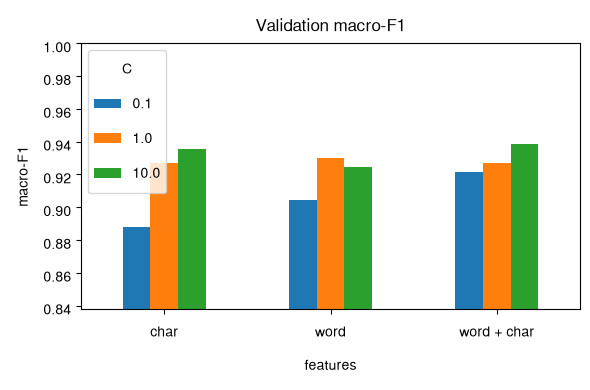

In [10]:
pivot = results.pivot(index="features", columns="C", values="val_macro_f1")
pivot.plot(kind="bar", figsize=(6, 4), ylim=(pivot.values.min() - 0.05, 1))
plt.title("Validation macro-F1")
plt.ylabel("macro-F1")
plt.xticks(rotation=0)
plt.legend(title="C")
plt.tight_layout()
plt.savefig("results/figures/02_tuning_validation.png", dpi=150)
plt.show()

- All 9 settings reach a validation macro-F1 between **0.888 and 0.938**.
- The best is **word + char features with `C = 10`** (0.938), just ahead of char only with `C = 10` (0.936).
- A small `C` (0.1, strong regularization) is always the worst: the model is too simple.

### 7. Model Evaluation (Test Sets)

We train the best setting again on the training set and use the two test sets **once**.

In [11]:
BEST_FEATURES, BEST_C = best["features"], float(best["C"])

def make_features(data):
    """TF-IDF features of the best setting (vectorizers already fitted on train)."""
    word = word_vectorizer.transform(data["tokens"])
    char = char_vectorizer.transform(data["text_km"])
    if BEST_FEATURES == "word":
        return word
    if BEST_FEATURES == "char":
        return char
    return hstack([word, char]).tocsr()

start = time.time()
model = make_model(BEST_C).fit(make_features(train), train["label_id"])
training_time = time.time() - start

print(f"Training time: {training_time:.1f} seconds")
n_parameters = count_parameters(model)

Training time: 0.6 seconds
Trainable weights: 65,481


#### Evaluation function

`evaluate_test_set` prints the classification report and draws the confusion matrix for one test set. First: **test_translated** (Khmer translations).

=== test_translated (358 reviews) ===
              precision    recall  f1-score   support

    negative      0.961     0.966     0.964       179
    positive      0.966     0.961     0.964       179

    accuracy                          0.964       358
   macro avg      0.964     0.964     0.964       358
weighted avg      0.964     0.964     0.964       358



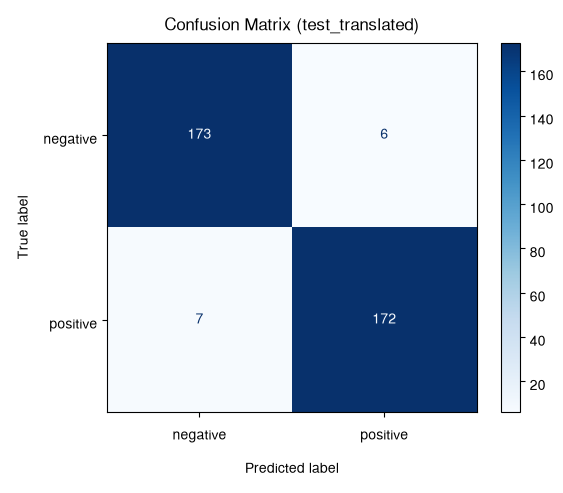

In [12]:
def evaluate_test_set(data, name):
    probs = model.predict_proba(make_features(data))     # one probability per class
    y_pred = probs.argmax(axis=1)
    y_true = data["label_id"].values
    print(f"=== {name} ({len(data)} reviews) ===")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=label_names, cmap='Blues')
    plt.title(f"Confusion Matrix ({name})")
    plt.savefig(f"results/figures/02_confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return y_pred, probs

y_pred_translated, probs_translated = evaluate_test_set(test_translated, "test_translated")

#### test_native: reviews written in Khmer (gold labels)

=== test_native (214 reviews) ===
              precision    recall  f1-score   support

    negative      0.968     0.894     0.930       170
    positive      0.684     0.886     0.772        44

    accuracy                          0.893       214
   macro avg      0.826     0.890     0.851       214
weighted avg      0.910     0.893     0.897       214



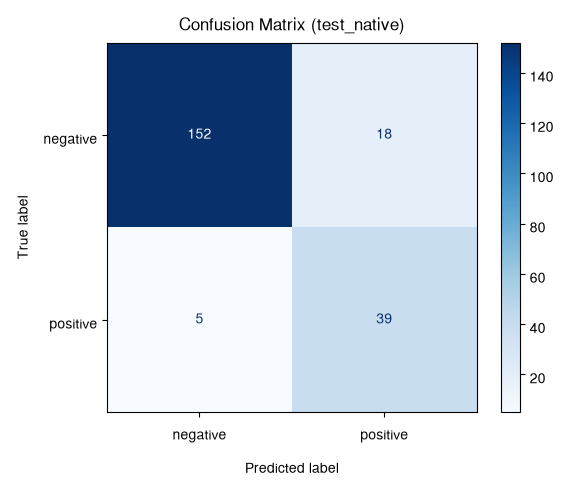

In [13]:
if LABEL_SOURCE == "silver":
    print("⚠ PROVISIONAL: test_native uses silver (AI) labels.\n")
y_pred_native, probs_native = evaluate_test_set(test_native, "test_native")

#### Pure Khmer vs. code-switched (inside test_native)

Does the model work as well on Khmer mixed with English words? (Only a few code-switched reviews → very uncertain.)

In [14]:
def macro_f1_by_group(data, y_pred):
    scores = {}
    for group in ["pure_khmer", "code_switched"]:
        mask = (data["language_group"] == group).values
        scores[group] = f1_score(data["label_id"].values[mask], y_pred[mask], average="macro",
                                 labels=[0, 1], zero_division=0)
        print(f"{group:14s}: {mask.sum():3d} reviews | macro-F1 = {scores[group]:.3f}")
    return scores

group_scores = macro_f1_by_group(test_native, y_pred_native)

pure_khmer    : 193 reviews | macro-F1 = 0.861
code_switched :  21 reviews | macro-F1 = 0.659


- **test_translated: macro-F1 0.964** (accuracy 96.4%), even a little higher than on validation.
- **test_native: macro-F1 0.851** (accuracy 89.3%, gold labels) → a **translation gap** of about 0.11 macro-F1:
  real Khmer reviews are harder than translated ones.
- On test_native the **positive** class is the weak one (F1 0.772, precision 0.684): many real **complaints are
  predicted as positive** (negative recall 0.894). Real Khmer complaints are often short and informal, unlike the
  translations the model learned from.
- **pure_khmer 0.861 vs. code_switched 0.659**, but there are only 21 code-switched reviews, so this difference is very uncertain.

### 8. Most Important Words

Logistic Regression is easy to **explain**: we can look at the weights.
- the **largest positive** weights → features that push a review towards **positive**
- the **most negative** weights → features that push a review towards **negative**

In [15]:
def feature_names():
    word = ["w: " + name for name in word_vectorizer.get_feature_names_out()]
    char = ["c: " + name for name in char_vectorizer.get_feature_names_out()]
    if BEST_FEATURES == "word":
        return np.array([name[3:] for name in word])
    if BEST_FEATURES == "char":
        return np.array([name[3:] for name in char])
    return np.array(word + char)    # "w:" = word feature, "c:" = character feature

def top_features(model, names, n=15):
    weights = model.coef_[0]
    order = weights.argsort()
    return pd.DataFrame({
        "negative feature": names[order[:n]], "weight (neg)": weights[order[:n]].round(2),
        "positive feature": names[order[::-1][:n]], "weight (pos)": weights[order[::-1][:n]].round(2),
    })

print(f"Best model ({BEST_FEATURES} features):")
top_features(model, feature_names())

Best model (word + char features):


,negative feature,weight (neg),positive feature,weight (pos)
0,w: មិន,-6.21,w: ល្អ,9.20
1,w: គ្មាន,-3.76,w: មាន,3.64
2,w: អន់,-3.25,w: ត្រូវ ម៉ោង,3.45
3,w: បើក,-2.70,c: ល្អ,3.16
4,w: ពេក,-2.65,c: ្អ,3.09
5,w: មិន ល្អ,-2.62,w: អរគុណ,3.07
6,w: អ្នកបើកបរ បើក,-2.58,w: រលូន,2.90
7,w: យឺត,-2.50,w: សូម ណែនាំ,2.82
8,w: កៅអី,-2.43,w: ពេញចិត្ត,2.77
9,w: មិន បាន,-2.41,w: ជួយ,2.76


Character pieces are hard to read, so we also train the **word-only** model (same `C`) just to see which **words** matter most.
This model is only used for this table.

In [16]:
word_model = make_model(BEST_C).fit(X_train_word, train["label_id"])
top_features(word_model, word_vectorizer.get_feature_names_out())

,negative feature,weight (neg),positive feature,weight (pos)
0,មិន,-9.28,ល្អ,14.47
1,គ្មាន,-5.35,ត្រូវ ម៉ោង,5.90
2,អន់,-4.82,អរគុណ,5.87
3,អ្នកបើកបរ បើក,-4.30,ពេញចិត្ត,5.22
4,បើក,-4.28,មាន,5.00
5,កៅអី,-4.14,រលូន,4.85
6,ទូរស័ព្ទ,-3.94,អស្ចារ្យ,4.68
7,ពេក,-3.77,រហ័ស,4.56
8,មិន បាន,-3.75,សូម ណែនាំ,4.55
9,មិន ល្អ,-3.72,មាន សុវត្ថិភាព,4.53


The word-only weights are easy to read:

| Negative words | Meaning | Positive words | Meaning |
|---|---|---|---|
| មិន | not | ល្អ | good |
| គ្មាន | there is no / without | ត្រូវ ម៉ោង | on time |
| អន់ | poor (quality) | អរគុណ | thank you |
| អ្នកបើកបរ បើក | the driver drives … | ពេញចិត្ត | satisfied |
| កៅអី | seat | រលូន | smooth |
| ទូរស័ព្ទ | phone | អស្ចារ្យ | amazing |
| ពេក | too (much) | សូម ណែនាំ | (I) recommend |
| មិន ល្អ | not good | មាន សុវត្ថិភាព | safe |
| យឺត | late | គ្មាន បញ្ហា | no problem |
| គ្រោះថ្នាក់ | danger / accident | ទាន់ ពេល | on time |

- The strongest negative feature is the negation word **មិន** ("not"): this is why we did **not** remove stopwords.
- **Bigrams help with negation**: គ្មាន ("there is no") alone is negative, but **គ្មាន បញ្ហា** ("no problem") is positive.
- **Topics** also get weights: កៅអី (seat), ទូរស័ព្ទ (phone, e.g. a driver on the phone) and
  អ្នកបើកបរ បើក ("the driver drives …") appear mostly in complaints. Even និង ("and") gets a positive weight: happy reviews
  often list several good things ("clean **and** on time **and** …"). The model learns what is *common* in each class,
  not what a word *means*.

### 9. Predict New Reviews

`predict()` does the same steps as training: `preprocess_text` → TF-IDF → model → probabilities.

We use the same **5 Khmer examples** in notebooks 02, 03 and 04:

| # | Review | Meaning | Expected |
|---|---|---|---|
| 1 | សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់ | very good service, friendly driver | positive |
| 2 | អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ | the driver doesn't really respect passengers (**negation**) | negative |
| 3 | ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់ | the bus left two hours late and the AC was not cold | negative |
| 4 | សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ | thank you very much, even though the bus was two hours late (**indirect complaint**) | negative |
| 5 | មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល | not bad, a comfortable trip (**negation → positive**) | positive |

In [17]:
def predict(text):
    tokens = preprocess_text(text)
    data = pd.DataFrame({"tokens": [" ".join(tokens)], "text_km": [text]})
    probs = model.predict_proba(make_features(data))[0]

    print(f"\n{text}")
    for name, prob in sorted(zip(label_names, probs), key=lambda x: x[1], reverse=True):
        print(f"  {name:8s}: {prob:.3f}")

NEW_REVIEWS = [
    "សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់",
    "អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ",
    "ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់",
    "សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ",
    "មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល",
]
for review in NEW_REVIEWS:
    predict(review)


សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់
  positive: 0.999
  negative: 0.001

អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ
  negative: 0.995
  positive: 0.005

ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់
  negative: 0.989
  positive: 0.011

សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ
  positive: 0.548
  negative: 0.452

មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល
  positive: 0.944
  negative: 0.056


- 4 of 5 examples are correct, including the negation in example 2 (**មិន**សូវគោរព … **ទេ**) and "not bad" in example 5.
- Example 4, the **indirect complaint** ("thank you very much, even though the bus was 2 hours late"), is wrong:
  **positive 0.548**. The model adds up អរគុណ ("thank you", positive) and យឺត ("late", negative) separately and does not
  understand that ទោះបី … ក៏ដោយ ("even though") turns the sentence into a complaint. It has no notion of context.

### 10. Save Predictions, Metrics and Model

| File | Content |
|---|---|
| `results/predictions/tfidf_logreg_{test set}.csv` | one row per review: true label, predicted label, probabilities |
| `results/metrics/tfidf_logreg.json` | accuracy and macro-F1 per test set, best validation macro-F1, settings |
| `models/tfidf_logreg.joblib` | the fitted vectorizers + model (used by the web app; not in git) |

In [18]:
def save_predictions(data, y_pred, probs, test_set):
    out = pd.DataFrame({
        "row_id": data["row_id"], "text_km": data["text_km"],
        "true_label": data["label"], "pred_label": [label_names[i] for i in y_pred],
        "prob_negative": probs[:, 0].round(4), "prob_positive": probs[:, 1].round(4),
    })
    out.to_csv(f"results/predictions/tfidf_logreg_{test_set}.csv", index=False, encoding="utf-8")

save_predictions(test_translated, y_pred_translated, probs_translated, "test_translated")
save_predictions(test_native, y_pred_native, probs_native, "test_native")

metrics = {
    "model": "tfidf_logreg",
    "model_type": "Statistical ML",
    "model_name": "TF-IDF + Logistic Regression",
    "input_features": f"TF-IDF ({BEST_FEATURES})",
    "uses_word_order": "partly (word bigrams)" if BEST_FEATURES != "char" else "no",
    "uses_context": "no",
    "trainable_parameters": int(n_parameters),
    "best_val_macro_f1": round(float(best["val_macro_f1"]), 4),
    "settings": {"features": BEST_FEATURES, "C": BEST_C, "class_weight": "balanced",
                 "word_ngram_range": [1, 2], "char_ngram_range": [2, 5], "min_df": 2},
    "training_time_sec": round(training_time, 2),
    "test_translated": {"accuracy": round(accuracy_score(test_translated["label_id"], y_pred_translated), 4),
                        "macro_f1": round(f1_score(test_translated["label_id"], y_pred_translated, average="macro"), 4)},
    "test_native": {"accuracy": round(accuracy_score(test_native["label_id"], y_pred_native), 4),
                    "macro_f1": round(f1_score(test_native["label_id"], y_pred_native, average="macro"), 4),
                    "pure_khmer_macro_f1": round(group_scores["pure_khmer"], 4),
                    "code_switched_macro_f1": round(group_scores["code_switched"], 4)},
    "test_native_label_source": LABEL_SOURCE,
}
with open("results/metrics/tfidf_logreg.json", "w") as f:
    json.dump(metrics, f, indent=2)

joblib.dump({"word_vectorizer": word_vectorizer, "char_vectorizer": char_vectorizer, "model": model,
             "features": BEST_FEATURES, "label_names": label_names}, "models/tfidf_logreg.joblib")

print(json.dumps(metrics, indent=2))

{
  "model": "tfidf_logreg",
  "model_type": "Statistical ML",
  "model_name": "TF-IDF + Logistic Regression",
  "input_features": "TF-IDF (word + char)",
  "uses_word_order": "partly (word bigrams)",
  "uses_context": "no",
  "trainable_parameters": 65481,
  "best_val_macro_f1": 0.9384,
  "settings": {
    "features": "word + char",
    "C": 10.0,
    "class_weight": "balanced",
    "word_ngram_range": [
      1,
      2
    ],
    "char_ngram_range": [
      2,
      5
    ],
    "min_df": 2
  },
  "training_time_sec": 0.6,
  "test_translated": {
    "accuracy": 0.9637,
    "macro_f1": 0.9637
  },
  "test_native": {
    "accuracy": 0.8925,
    "macro_f1": 0.851,
    "pure_khmer_macro_f1": 0.8614,
    "code_switched_macro_f1": 0.6595
  },
  "test_native_label_source": "gold"
}


### 11. Observations

- **Results** (best setting: word + char TF-IDF, `C = 10`, 65,481 weights, trained in about half a second on a normal CPU):

| Test set | Accuracy | Macro-F1 |
|---|---|---|
| test_translated | 0.964 | **0.964** |
| test_native (gold labels) | 0.893 | **0.851** |

- **Translation gap**: about −0.11 macro-F1 from translated to real Khmer reviews. Real Khmer reviews are shorter,
  more informal and 79% negative; the model predicts too many of their complaints as positive.
- **Interpretable**: the weights show clear sentiment words (ល្អ good, អរគុណ thank you, ពេញចិត្ត satisfied vs.
  មិន not, អន់ poor, យឺត late), and bigrams partly handle negation (គ្មាន បញ្ហា "no problem" → positive).
- **Limits**: no word order beyond bigrams and no context, so indirect complaints ("thank you, even though …") fool it.
- This is a **strong baseline**: notebooks 03 (BiLSTM) and 04 (XLM-R) must beat 0.964 / 0.851 to be worth their extra cost.